In [1]:
from pathlib import Path
import random
import yaml
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
dataset_path = Path("../datasets/construction-ppe-small")

with open(dataset_path / "data.yaml") as file:
    data = yaml.safe_load(file)

class_names = data["names"]

print("Dataset:", dataset_path)
print("Number of classes:", len(class_names))

class_names

Dataset: ../datasets/construction-ppe-small
Number of classes: 12


{0: 'helmet',
 1: 'gloves',
 2: 'vest',
 3: 'boots',
 4: 'goggles',
 5: 'Person',
 6: 'no_helmet',
 7: 'no_goggle',
 8: 'no_gloves',
 9: 'no_boots',
 10: 'forklift',
 11: 'no_vest'}

In [3]:
def show_random_image(split="train"):
    images_dir = dataset_path / "images" / split
    labels_dir = dataset_path / "labels" / split

    image_paths = sorted(
        p for p in images_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    image_path = random.choice(image_paths)
    label_path = labels_dir / f"{image_path.stem}.txt"

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(f"Construction-PPE | {split}")

    colors = plt.get_cmap("tab20")

    for line in label_path.read_text().splitlines():
        cls, x, y, w, h = map(float, line.split())
        cls = int(cls)

        x_min = (x - w / 2) * width
        y_min = (y - h / 2) * height

        color = colors(cls)

        rect = patches.Rectangle(
            (x_min, y_min),
            w * width,
            h * height,
            linewidth=2,
            edgecolor=color,
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x_min, y_min,
            class_names[cls],
            color="white",
            fontsize=9,
            bbox=dict(facecolor=color, alpha=0.85)
        )

    plt.show()

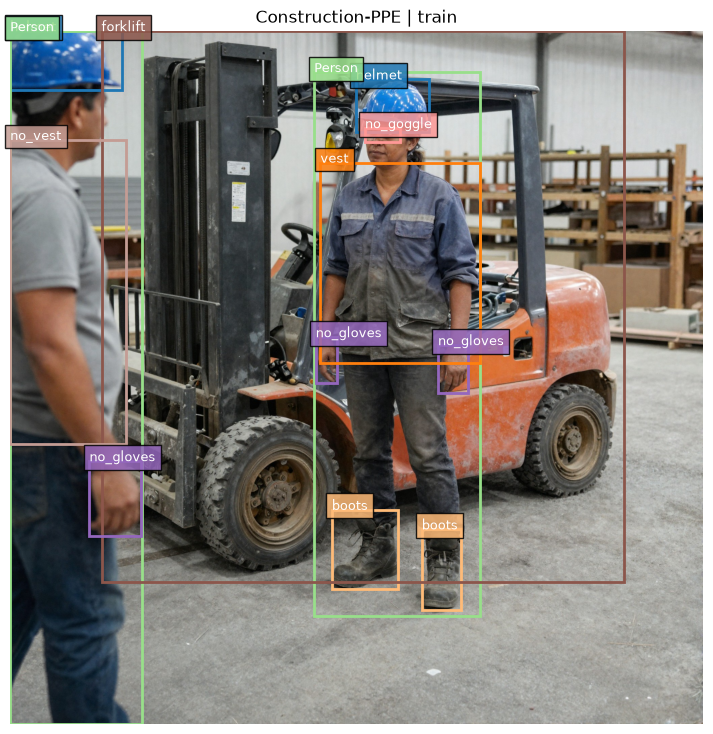

In [4]:
show_random_image("train")

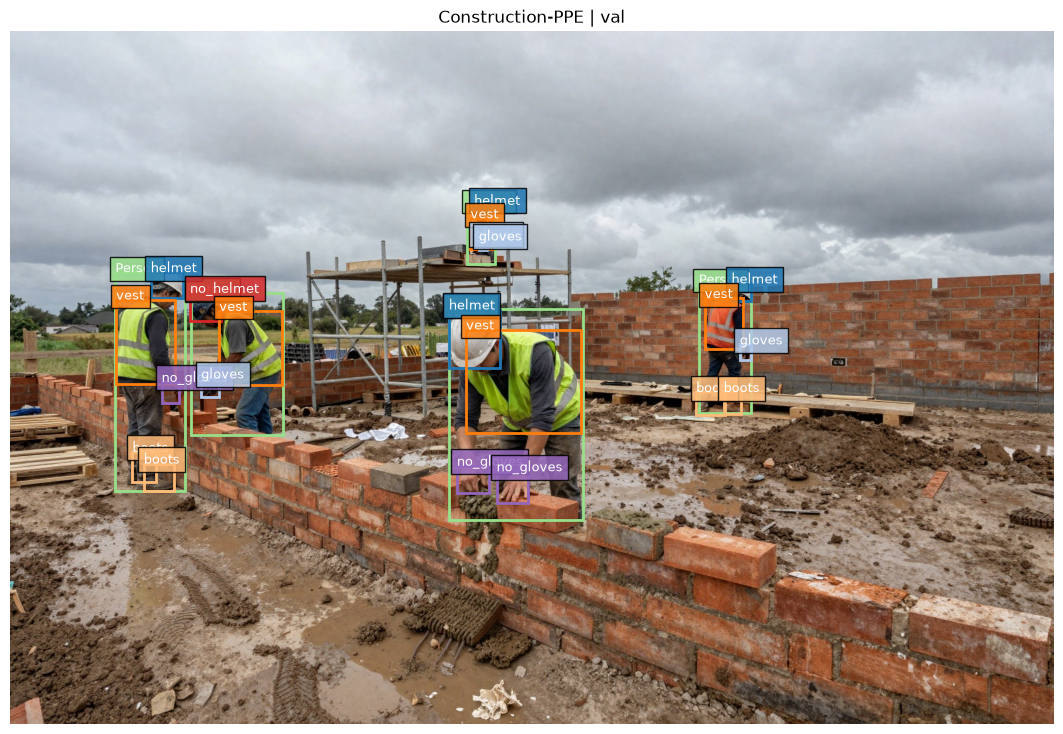

In [5]:
show_random_image("val")

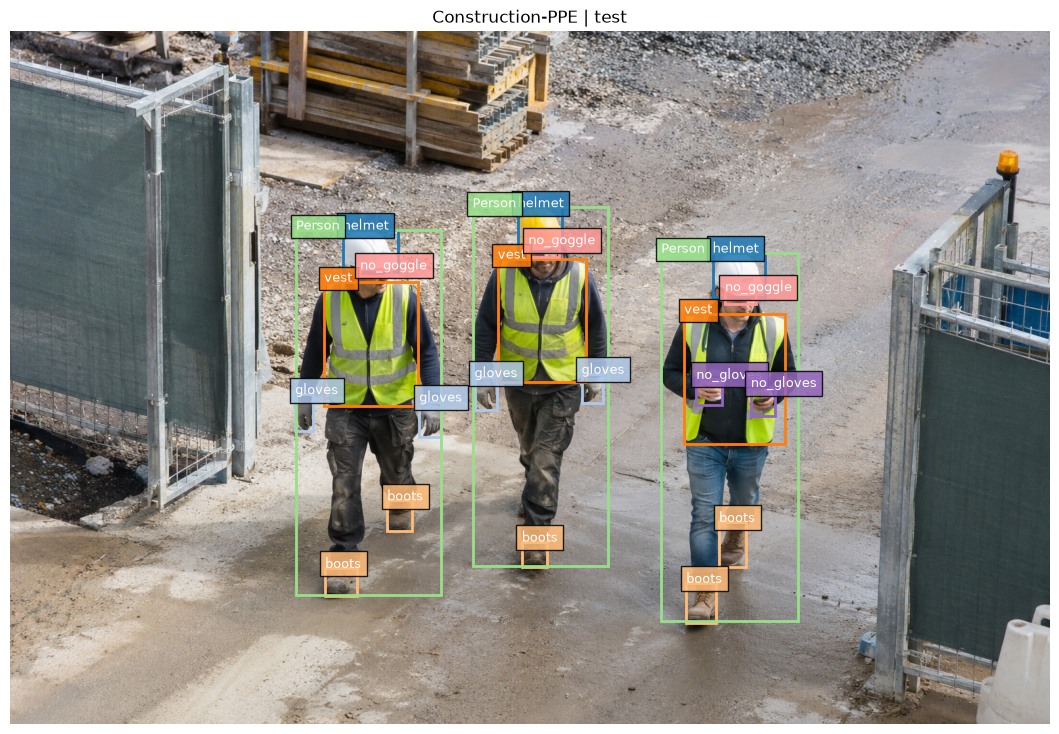

In [6]:
show_random_image("test")